# Zela | Redes Neurais Artificiais

**Integrantes**
- Naiara Sousa Soares, RM 574792
- Rafael Medici, RM 576249
- Kayky Cayres Vicente da Silva, RM 575091

## 1. Problema e aplicação

A Zela olha para um problema real do pronto-socorro, pacientes que esperam muito tempo e acabam piorando durante essa espera sem que ninguém perceba. A pulseira mede os sinais vitais de quem está na sala de espera e avisa a equipe quando a leitura chega ao nível de atenção ou crítico.

A rede neural entra antes desse alerta. Ela prevê se o paciente vai chegar ao nível crítico nos próximos 10 minutos, para que a equipe consiga avaliar esse paciente antes da crise. É uma tarefa de **classificação** (sim ou não).

- **Entradas (X)**, 8 features, que são o tempo de espera, os 3 sinais vitais que a pulseira mede (frequência cardíaca, saturação de oxigênio e temperatura) e 4 features de variação em relação ao normal do próprio paciente. A pressão arterial não entra, porque a pulseira não mede.
- **Saída (y)**, `vai_ficar_critico`, que vale 1 se alguma das próximas 5 leituras (10 minutos) for crítica, 0 se não.

Os dados, o alvo e o pré-processamento são os mesmos do notebook de Machine Learning, onde está a análise exploratória completa. Aqui o foco é a MLP.

## 2. Dataset

Para o modelo, partimos de um dataset real e geramos uma versão simulada a partir dele. A base real é a *Five Vital Signs of Normal People*, publicada no Zenodo (https://zenodo.org/records/5549632?preview_file=five+vital+signs+of+normal+people.csv). Ela traz os sinais vitais de 102 pessoas sem doença, medidos por um médico 3 vezes por dia durante 3 dias, ou seja, 9 leituras por pessoa. Os sinais são pressão diastólica, pressão sistólica, frequência cardíaca, saturação de oxigênio e temperatura. O dataset tem 102 linhas, uma por pessoa, e 46 colunas, com o ID e as 9 leituras de cada um dos 5 sinais.

Simulamos porque não existe base pública de pessoas piorando enquanto esperam no pronto-socorro, que é justamente o que a Zela observa. Para cada pessoa, usamos a mediana das 9 leituras como o "normal" dela e, a partir disso, geramos 36 leituras seguidas, uma a cada 2 minutos (0 a 70 min de espera), como se a pulseira estivesse medindo na sala de espera. Cada pessoa recebeu um destes cenários, estável, frequência cardíaca subindo, saturação de oxigênio caindo, combinado ou recuperação. Os sinais mudam aos poucos conforme o cenário (a temperatura sobe bem mais no combinado e no de frequência cardíaca subindo), e colocamos um pequeno ruído para não ficar artificialmente liso. A base final tem 3.672 linhas (102 pessoas × 36 leituras) e 13 colunas, com a data e a hora de cada leitura.

Os cenários e o tamanho de cada mudança foram definidos pelo grupo e não seguem um critério clínico. A base real só tem pessoas saudáveis e não informa idade, país nem o aparelho usado. Por isso, o modelo aprende o padrão da nossa simulação. Antes de ser usado em um cenário real, ele precisaria ser treinado com dados reais de pronto-socorro.

Esses dados permitem treinar uma MLP porque são dados tabulares e, depois do pré-processamento, todas as 8 features que entram na rede são numéricas. As colunas de texto ficam de fora. O alvo é definido para cada leitura, sim ou não, o que torna a tarefa uma classificação. São `3.027` leituras de `102` pacientes, o suficiente para uma rede pequena. Além disso, a piora depende da combinação dos sinais, como a frequência cardíaca subindo junto com a saturação caindo, e a MLP consegue aprender essas combinações.

In [1]:
# importando as bibliotecas necessárias para a análise do dataset e visualização em gráficos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# carregando o dataset
df = pd.read_csv('dados/medicoes_pulseira_simuladas.csv')


In [2]:
df.shape # número de linhas e colunas

(3672, 13)

In [3]:
df.info() # informações dos dados

<class 'pandas.DataFrame'>
RangeIndex: 3672 entries, 0 to 3671
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   paciente_id          3672 non-null   int64  
 1   dispositivo_id       3672 non-null   str    
 2   leitura_numero       3672 non-null   int64  
 3   tempo_espera_min     3672 non-null   int64  
 4   dt_medicao           3672 non-null   str    
 5   frequencia_cardiaca  3672 non-null   int64  
 6   spo2                 3672 non-null   float64
 7   temperatura          3672 non-null   float64
 8   pressao_sistolica    3672 non-null   int64  
 9   pressao_diastolica   3672 non-null   int64  
 10  cenario_simulado     3672 non-null   str    
 11  origem_dado          3672 non-null   str    
 12  fonte_referencia     3672 non-null   str    
dtypes: float64(2), int64(6), str(5)
memory usage: 373.1 KB


In [4]:
df.head() # primeiras 5 linhas

,paciente_id,dispositivo_id,leitura_numero,tempo_espera_min,dt_medicao,frequencia_cardiaca,spo2,temperatura,pressao_sistolica,pressao_diastolica,cenario_simulado,origem_dado,fonte_referencia
0,1,ESP32-0001,1,0,2026-11-10 14:00:00,74,97.1,35.87,112,67,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
1,1,ESP32-0001,2,2,2026-11-10 14:02:00,73,96.9,35.92,111,66,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
2,1,ESP32-0001,3,4,2026-11-10 14:04:00,75,97.2,35.94,110,67,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
3,1,ESP32-0001,4,6,2026-11-10 14:06:00,74,97.0,35.99,110,64,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...
4,1,ESP32-0001,5,8,2026-11-10 14:08:00,73,97.3,35.98,109,66,ESTAVEL,SIMULADO,Simulado - faixas inspiradas no dataset Zenodo...


Podemos ver que o dataset tem 3672 linhas e 13 colunas, cada linha é um momento da espera de um paciente, as colunas trazem a identificação, o tempo de espera, a data e a hora da leitura, os 5 sinais vitais e o cenário simulado. Todas as linhas e colunas estão preenchidas, nenhum valor é nulo. 8 colunas são numéricas e 5 são de texto, e a data e hora (`dt_medicao`) vem como texto. Dos 5 sinais, a pulseira real só mede frequência cardíaca, SpO2 e temperatura, então a pressão sistólica e a diastólica ficam só na análise e não entram no modelo.

| Coluna | O que é | Unidade / valores |
|---|---|---|
| paciente_id | identificador da pessoa | 1 a 102 |
| dispositivo_id | identificador da pulseira, uma por pessoa | ESP32-0001 a ESP32-0102 |
| leitura_numero | ordem da leitura daquela pessoa | 1 a 36 |
| tempo_espera_min | minutos desde a chegada na sala de espera | 0 a 70, de 2 em 2 |
| dt_medicao | data e hora da leitura | de 2026-11-10 14:00 a 23:35 |
| frequencia_cardiaca | batimentos do coração por minuto | bpm |
| spo2 | saturação de oxigênio no sangue | % |
| temperatura | temperatura corporal | °C |
| pressao_sistolica | pressão arterial máxima | mmHg |
| pressao_diastolica | pressão arterial mínima | mmHg |
| cenario_simulado | cenário atribuído à pessoa na simulação | ESTAVEL, FC_ELEVANDO, SPO2_CAINDO, COMBINADO, RECUPERACAO |
| origem_dado | indica que a linha é simulada | sempre "SIMULADO" |
| fonte_referencia | de onde vieram as faixas da simulação | sempre o mesmo texto: simulado, com faixas inspiradas no Zenodo |


In [5]:
df.isna().sum() # verificar valores nulos

paciente_id            0
dispositivo_id         0
leitura_numero         0
tempo_espera_min       0
dt_medicao             0
frequencia_cardiaca    0
spo2                   0
temperatura            0
pressao_sistolica      0
pressao_diastolica     0
cenario_simulado       0
origem_dado            0
fonte_referencia       0
dtype: int64

In [6]:
df.duplicated().sum() # verificar duplicatas

np.int64(0)

Analisamos que não há nenhum dado faltante, assim como vimos antes, e nem dado duplicado. Isso já era esperado, porque a base foi gerada artificialmente.

In [7]:
# dt_medicao é a data e a hora da leitura, conferimos se ela concorda com o tempo de espera
df['dt_medicao'] = pd.to_datetime(df['dt_medicao'])
minutos = (df['dt_medicao'] - df.groupby('paciente_id')['dt_medicao'].transform('min')).dt.total_seconds() / 60
print('dt_medicao vai de', df['dt_medicao'].min(), 'até', df['dt_medicao'].max())
print('Leituras em que dt_medicao não bate com tempo_espera_min:', (minutos != df['tempo_espera_min']).sum())

dt_medicao vai de 2026-11-10 14:00:00 até 2026-11-10 23:35:00
Leituras em que dt_medicao não bate com tempo_espera_min: 0


A coluna `dt_medicao` guarda a data e a hora de cada leitura. Conferimos que ela concorda com o `tempo_espera_min`, sem nenhuma diferença nas 3.672 leituras, porque cada paciente chega num horário e as leituras seguem de 2 em 2 minutos. Como ela só repete o tempo de espera, e o horário de chegada não diz nada sobre o estado do paciente, a coluna não entra como feature.

In [8]:
# regra de crítico, a mesma do monitor em Python e da pulseira (FC, SpO2 e temperatura)
df = df.sort_values(['paciente_id', 'tempo_espera_min'])
df['critico'] = ((df['frequencia_cardiaca'] >= 130) | (df['spo2'] < 90) | (df['temperatura'] >= 39.0)).astype(int)

# alvo: alguma das próximas 5 leituras (10 min) do mesmo paciente é crítica?
proximas = [df.groupby('paciente_id')['critico'].shift(-k) for k in range(1, 6)]
df['vai_ficar_critico'] = pd.concat(proximas, axis=1).max(axis=1)

df[['paciente_id', 'tempo_espera_min', 'frequencia_cardiaca', 'spo2', 'temperatura', 'critico', 'vai_ficar_critico']].head(40)

,paciente_id,tempo_espera_min,frequencia_cardiaca,spo2,temperatura,critico,vai_ficar_critico
0,1,0,74,97.1,35.87,0,0.0
1,1,2,73,96.9,35.92,0,0.0
2,1,4,75,97.2,35.94,0,0.0
3,1,6,74,97.0,35.99,0,0.0
4,1,8,73,97.3,35.98,0,0.0
5,1,10,77,96.9,36.08,0,0.0
6,1,12,74,97.5,36.12,0,0.0
7,1,14,76,97.2,36.06,0,0.0
8,1,16,76,96.8,35.98,0,0.0
9,1,18,77,97.9,35.93,0,0.0


Leituras para o modelo: 3027
vai_ficar_critico
0.0    0.907
1.0    0.093
Name: proportion, dtype: float64


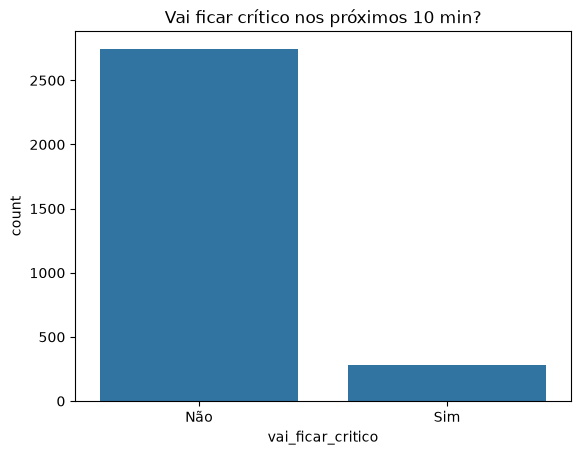

In [9]:
# o modelo só faz sentido para quem ainda NÃO está crítico e tem leituras futuras
base = df[(df['critico'] == 0) & df['vai_ficar_critico'].notna()]

print('Leituras para o modelo:', len(base))
print(base['vai_ficar_critico'].value_counts(normalize=True).round(3))

sns.countplot(data=base, x='vai_ficar_critico')
plt.title('Vai ficar crítico nos próximos 10 min?')
plt.xticks([0, 1], ['Não', 'Sim'])
plt.show()

O alvo é `vai_ficar_critico`, o modelo tenta prever se, nos próximos 10 minutos, o paciente vai chegar ao nível crítico. Se só classificássemos o estado atual, seria uma detecção, e isso a regra da pulseira já faz. Como a base real não tem horário nem pacientes piorando, criamos esse target experimental a partir dos cenários simulados, usando só as informações disponíveis até o momento da leitura.

O nível crítico segue a regra da pulseira e do monitor em Python, frequência cardíaca de 130 bpm ou mais, SpO2 abaixo de 90% ou temperatura de 39,0 °C ou mais. A temperatura entrou na regra porque a pulseira também lê a temperatura, e assim o crítico do modelo é o mesmo que a equipe veria na pulseira. No total, 122 leituras passam de 39,0 °C, em 15 pacientes, e 6 leituras de 3 pacientes ficaram críticas só pela temperatura, as outras já eram críticas pela frequência cardíaca ou pela saturação.

As leituras que já são críticas saem da base, porque a pulseira já captou esse estado e não há o que prever. A última leitura de cada paciente também sai, porque não tem leituras futuras para dizer se ele ficou crítico.

A base é desbalanceada, 91% das leituras são "não" e só 9% são "sim". Isso acontece porque, mesmo nos cenários de piora, só as leituras dos 10 minutos antes de virar crítico entram como "sim". Por isso a acurácia engana, um modelo que sempre respondesse "não" acertaria 91% sem servir para nada. Vamos olhar principalmente o recall e a precisão.

# 3. Preparação dos dados

**Valores estranhos**

Na base original havia alguns dados inconsistentes, como saturação de oxigênio acima de 100% (até 102%) e temperatura muito baixa (até 33,1 °C). Não sabemos o motivo, porque a base original não informa como as medições foram feitas. Na nossa base, a saturação acima de 100% não aparece, porque a simulação limita a SpO2 em 100%. A temperatura baixa continua, com 85 leituras abaixo de 35 °C, de 8 pacientes. Uma hipótese é que a temperatura tenha sido medida na pele ou no pulso, que fica abaixo da temperatura interna do corpo. Decidimos manter a temperatura, porque a pulseira mede temperatura de verdade e as leituras baixas não atrapalham a regra de crítico, que olha só para temperaturas altas (39,0 °C ou mais).

**Colunas que saem do modelo**

- `leitura_numero` é a mesma informação do `tempo_espera_min`. Não precisamos dessa redundância.
- `paciente_id` e `dispositivo_id` são identificadores e não dizem nada sobre o estado do paciente. O `paciente_id` só fica guardado para separar treino e teste por paciente.
- `origem_dado` e `fonte_referencia` têm o mesmo valor em todas as linhas, então não ajudam o modelo.
- `cenario_simulado` entrega a resposta, porque diz se o paciente vai piorar, e a pulseira real não teria essa informação. Usar essa coluna seria data leakage.
- `pressao_sistolica` e `pressao_diastolica` ficam na análise, mas saem do modelo, porque a pulseira (ESP32) só mede frequência cardíaca, SpO2 e temperatura. Em uso real o modelo não teria essa informação.
- `dt_medicao` é a data e a hora da leitura e só repete o `tempo_espera_min`, além de mostrar o horário em que cada paciente chegou, que não diz nada sobre o estado dele.

In [10]:
# features de variação, comparando cada leitura com o normal da própria pessoa
paciente = df.groupby('paciente_id')

df['fc_variacao'] = df['frequencia_cardiaca'] - paciente['frequencia_cardiaca'].transform('first')
df['spo2_variacao'] = df['spo2'] - paciente['spo2'].transform('first')

# maior variação até agora, guarda a pior piora, mesmo que o paciente melhore depois
df['fc_maior_subida'] = df.groupby('paciente_id')['fc_variacao'].cummax()
df['spo2_maior_queda'] = df.groupby('paciente_id')['spo2_variacao'].cummin()

df[df['paciente_id'] == 3][['tempo_espera_min', 'frequencia_cardiaca', 'fc_variacao', 'fc_maior_subida',
                            'spo2', 'spo2_variacao', 'spo2_maior_queda']].iloc[::5]

,tempo_espera_min,frequencia_cardiaca,fc_variacao,fc_maior_subida,spo2,spo2_variacao,spo2_maior_queda
72,0,90,0,0,96.7,0.0,0.0
77,10,89,-1,0,95.6,-1.1,-1.1
82,20,89,-1,2,94.5,-2.2,-2.4
87,30,92,2,2,94.0,-2.7,-2.7
92,40,98,8,8,91.4,-5.3,-5.3
97,50,99,9,12,89.9,-6.8,-6.8
102,60,102,12,12,90.3,-6.4,-8.1
107,70,106,16,16,88.0,-8.7,-8.9


As features de variação comparam cada leitura com a primeira leitura da própria pessoa, que serve como referência do seu normal. Assim o modelo faz uma comparação mais justa, uma FC de 100 pode ser normal para uma pessoa e uma piora para outra. A maior variação até agora guarda a pior piora que a pessoa já teve na espera, para o modelo não esquecer quem piorou e depois melhorou, porque essa pessoa ainda pode voltar a piorar.

In [11]:
# base do modelo, só leituras ainda não críticas e com leituras futuras
base = df[(df['critico'] == 0) & df['vai_ficar_critico'].notna()].copy()

# entradas (X) e saída (y), as colunas descartadas na EDA e a pressão (a pulseira não mede) ficam de fora
features = ['tempo_espera_min', 'frequencia_cardiaca', 'spo2', 'temperatura',
            'fc_variacao', 'spo2_variacao', 'fc_maior_subida', 'spo2_maior_queda']

X = base[features]
y = base['vai_ficar_critico'].astype(int)
print('X:', X.shape, '| y:', y.shape)

X: (3027, 8) | y: (3027,)


In [12]:
from sklearn.model_selection import train_test_split

# holdout por paciente, todas as leituras de um paciente ficam só no treino ou só no teste
pacientes = base.groupby('paciente_id')['vai_ficar_critico'].max()
treino_ids, teste_ids = train_test_split(pacientes.index, test_size=0.2,
                                         stratify=pacientes, random_state=42)

no_treino = base['paciente_id'].isin(treino_ids)
X_train, X_test = X[no_treino], X[~no_treino]
y_train, y_test = y[no_treino], y[~no_treino]

print('Pacientes  treino:', len(treino_ids), '| teste:', len(teste_ids))
print('Leituras   treino:', len(X_train), '| teste:', len(X_test))
print('% que vai ficar crítico  treino:', round(y_train.mean(), 3), '| teste:', round(y_test.mean(), 3))
print('Pacientes nos dois conjuntos:', len(set(treino_ids) & set(teste_ids)))

Pacientes  treino: 81 | teste: 21
Leituras   treino: 2401 | teste: 626
% que vai ficar crítico  treino: 0.094 | teste: 0.091
Pacientes nos dois conjuntos: 0


O split é feito por paciente, e não por leitura. Se as leituras do mesmo paciente caíssem no treino e no teste, o modelo iria reconhecer esse paciente e decorar os dados dele, e o resultado no teste sairia melhor do que seria com um paciente novo.

In [13]:
from sklearn.preprocessing import StandardScaler

# padronização, média 0 e desvio 1, o fit usa SÓ o treino para o teste não vazar
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

pd.DataFrame(X_train_esc, columns=features).describe().round(2).loc[['mean', 'std']]

,tempo_espera_min,frequencia_cardiaca,spo2,temperatura,fc_variacao,spo2_variacao,fc_maior_subida,spo2_maior_queda
mean,0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


O StandardScaler deixa todas as features na mesma escala (média 0 e desvio 1). O modelo só enxerga números, por exemplo uma variação de 5 na saturação de oxigênio é grave, enquanto 5 batimentos a mais na frequência cardíaca mudam pouco, mas sem a padronização a feature com valores maiores acabaria pesando mais. O fit, que calcula a média e o desvio, é feito só com o treino, e o teste é transformado com esses mesmos valores. Se o teste entrasse no cálculo, seria como estudar para a prova com as respostas já prontas.

O StandardScaler é ainda mais importante numa MLP, porque a rede começa com pesos aleatórios e vai ajustando os pesos e o viés aos poucos, a cada iteração. Se uma feature tem valores muito maiores que outra, esses ajustes ficam desequilibrados, e a rede demora muito para aprender ou nem chega a convergir. Com tudo na mesma escala, o treino fica mais estável.

# 4. A MLP

Escolhemos uma rede com 8 entradas, que são as features, uma camada oculta com 8 neurônios e uma saída. Essa saída é a chance de o paciente ficar crítico, de 0 a 100%. É uma rede pequena porque a base tem poucas leituras e só 8 features.

Cada neurônio multiplica as entradas por pesos, soma o viés e passa o resultado pela função de ativação. A ativação é a `relu`, que zera o resultado quando ele é negativo, e é ela que deixa a rede aprender combinações não lineares entre os sinais. O `adam` é o otimizador que ajusta os pesos durante o treino. Os dois são o padrão do scikit-learn e não alteramos nenhum.

O fluxo começa com a leitura da pulseira, que passa pelo StandardScaler com a média e o desvio padrão do treino. Depois entra na MLP, que devolve a chance de o paciente ficar crítico, e avisa se essa chance passar do limiar.

In [14]:
from sklearn.neural_network import MLPClassifier

# 1 camada oculta com 8 neurônios, random_state fixo para o resultado ser reproduzível
mlp = MLPClassifier(hidden_layer_sizes=(8,), max_iter=1000, random_state=42)
mlp.fit(X_train_esc, y_train)  # só o treino, o teste fica guardado para a avaliação

print('Camadas ocultas:', mlp.hidden_layer_sizes)
print('Função de ativação:', mlp.activation, '| otimizador:', mlp.solver)
print('Iterações até parar:', mlp.n_iter_, 'de', mlp.max_iter)
print('Perda (loss) final no treino:', round(mlp.loss_, 3))

Camadas ocultas: (8,)
Função de ativação: relu | otimizador: adam
Iterações até parar: 273 de 1000
Perda (loss) final no treino: 0.124


# 5. Treinamento

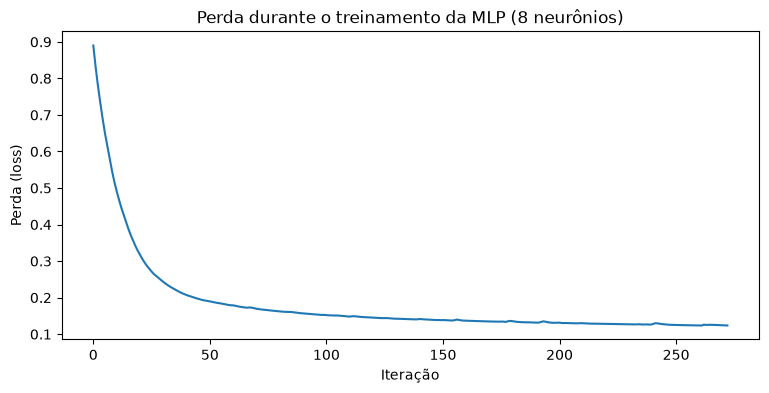

In [15]:
# curva da perda (loss), quanto a rede ainda erra no treino a cada iteração
plt.figure(figsize=(9, 4))
plt.plot(mlp.loss_curve_)
plt.title('Perda durante o treinamento da MLP (8 neurônios)')
plt.xlabel('Iteração')
plt.ylabel('Perda (loss)')
plt.show()

Analisando a curva da perda, podemos ver que ela cai rapidamente nas primeiras 50 iterações, de `0,89` para `0,19`. Depois, a queda fica mais lenta e, a partir da iteração 200, cai bem devagar. A rede parou sozinha na iteração `273`, antes do limite de `1000`, porque a perda deixou de melhorar. Uma perda baixa no treino não garante acerto em pacientes que a rede nunca viu, isso só a avaliação no teste mostra.

# 6. Ajuste simples

In [16]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

# validação cruzada dentro do treino, separando por paciente, o teste não entra na escolha
grupos = base.loc[no_treino, 'paciente_id']
validacao = GroupKFold(n_splits=5)

def chances_validacao(neuronios):
    # para cada parte da validação: scaler ajustado só nas outras partes, MLP treinada e chance prevista
    chances = pd.Series(0.0, index=y_train.index)
    for idx_treino, idx_valid in validacao.split(X_train, y_train, grupos):
        esc = StandardScaler().fit(X_train.iloc[idx_treino])
        rede = MLPClassifier(hidden_layer_sizes=neuronios, max_iter=1000, random_state=42)
        rede.fit(esc.transform(X_train.iloc[idx_treino]), y_train.iloc[idx_treino])
        chances.iloc[idx_valid] = rede.predict_proba(esc.transform(X_train.iloc[idx_valid]))[:, 1]
    return chances

def metricas(y_real, y_prev):
    return {'acurácia': accuracy_score(y_real, y_prev), 'recall': recall_score(y_real, y_prev),
            'precisão': precision_score(y_real, y_prev), 'F1': f1_score(y_real, y_prev)}

# muda só um elemento, o número de neurônios. Mesma divisão, mesmo scaler, mesmas métricas
linhas = {}
for neuronios in [(32,), (8,)]:
    chances = chances_validacao(neuronios)
    rede = MLPClassifier(hidden_layer_sizes=neuronios, max_iter=1000, random_state=42).fit(X_train_esc, y_train)
    validacao_m = metricas(y_train, (chances >= 0.5).astype(int))
    linhas[f'{neuronios[0]} neurônios'] = {
        'loss treino': rede.loss_, 'recall validação': validacao_m['recall'], 'precisão validação': validacao_m['precisão']}

comparacao = pd.DataFrame(linhas).T.round(3)
comparacao

,loss treino,recall validação,precisão validação
32 neurônios,0.106,0.712,0.679
8 neurônios,0.124,0.650,0.681


Testamos uma segunda rede para fazer a comparação, mudando apenas o número de neurônios, 32 no lugar de 8. A divisão dos dados, o StandardScaler e as métricas são os mesmos. Com o limiar padrão de `0,5`, a rede com 32 neurônios acerta mais no treino (perda `0,106` contra `0,124`) e tem um recall maior na validação (`0,71` contra `0,65`), com a mesma precisão (`0,68` nas duas). Só que o modelo final não usa o limiar de `0,5`, então essa comparação sozinha não decide. A escolha entre as duas redes é conferida de novo no limiar final, logo abaixo, só com a validação, porque o teste fica para o resultado final.

In [17]:
# a MLPClassifier não tem class_weight, então tratamos o desbalanceamento pelo limiar:
# a rede avisa quando a chance passa do limiar, e um limiar menor avisa mais pacientes
# o limiar vale para as duas redes, então a escolha entre 8 e 32 neurônios também é conferida em cada limiar
chances = {neuronios: chances_validacao((neuronios,)) for neuronios in [8, 32]}
limiares = pd.DataFrame({(f'{neuronios} neurônios', limiar): metricas(y_train, (chances[neuronios] >= limiar).astype(int))
                         for neuronios in [8, 32] for limiar in [0.5, 0.3, 0.2, 0.1]}).T.round(3)
limiares.index.names = ['rede', 'limiar']
limiares

acurácia  recall  precisão     F1
rede         limiar                                   
8 neurônios  0.5        0.938   0.650     0.681  0.665
             0.3        0.931   0.774     0.606  0.680
             0.2        0.920   0.841     0.549  0.664
             0.1        0.899   0.907     0.481  0.629
32 neurônios 0.5        0.941   0.712     0.679  0.695
             0.3        0.933   0.779     0.615  0.688
             0.2        0.931   0.841     0.594  0.696
             0.1        0.915   0.867     0.531  0.659

Como a `MLPClassifier` não tem `class_weight`, que foi o que usamos no ML para tratar o desbalanceamento, ajustamos o limiar. A rede dá uma chance de 0 a 100% de o paciente ficar crítico, e o aviso acontece quando essa chance passa do limiar. Como só 9% das leituras são "sim", a rede raramente passa de 50%, e com o limiar padrão de `0,5` ela deixa passar muitos pacientes. Quanto menor o limiar, mais pacientes ela avisa, mas também dá mais alarmes falsos. Escolhemos o limiar de `0,1`, porque, assim como no ML, a prioridade é não deixar passar quem vai piorar. Nas duas redes é ele que dá o maior recall. Na rede de 8 neurônios, o recall na validação é `0,91` com precisão de `0,48`, próximo da Regressão Logística do ML (`0,92` e `0,43`).

A tabela também compara as duas redes em cada limiar. No limiar de `0,1`, a rede de 8 neurônios tem recall de `0,91` contra `0,87` da rede de 32, e a de 32 tem uma precisão maior (`0,53` contra `0,48`). Como o recall vem primeiro, a rede de 8 neurônios é a melhor, e ela ainda é a menor das duas. A diferença é de uns 4 pontos de recall em 81 pacientes, então é pequena, e nos limiares de `0,3` e `0,2` as duas redes ficam empatadas no recall. Por isso mantivemos a de 8 neurônios, mas essa escolha é apertada.

# 7. Avaliação

,"MLP (8 neurônios, limiar 0,1)",Regressão Logística (ML)
acurácia,0.877,0.899
recall,0.930,0.895
precisão,0.421,0.472
F1,0.579,0.618


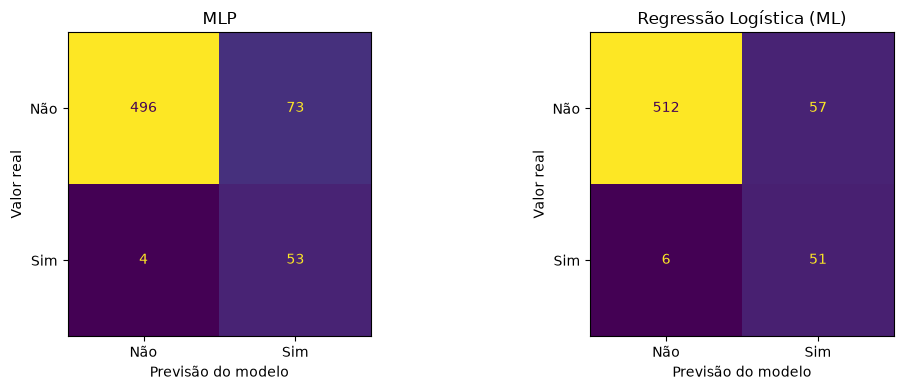

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

LIMIAR = 0.1  # escolhido na validação cruzada acima
prev_mlp = (mlp.predict_proba(X_test_esc)[:, 1] >= LIMIAR).astype(int)

# a Regressão Logística do notebook de ML, mesma divisão e mesmo scaler, só como referência
logistica = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42).fit(X_train_esc, y_train)
prev_logistica = logistica.predict(X_test_esc)

resultados = pd.DataFrame({'MLP (8 neurônios, limiar 0,1)': metricas(y_test, prev_mlp),
                           'Regressão Logística (ML)': metricas(y_test, prev_logistica)}).round(3)
display(resultados)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nome, prev) in zip(axes, [('MLP', prev_mlp), ('Regressão Logística (ML)', prev_logistica)]):
    ConfusionMatrixDisplay.from_predictions(y_test, prev, display_labels=['Não', 'Sim'], ax=ax, colorbar=False)
    ax.set_title(nome)
    ax.set_xlabel('Previsão do modelo')
    ax.set_ylabel('Valor real')
plt.tight_layout()
plt.show()

No teste, a MLP avisou `53` dos `57` casos que iam ficar críticos e deixou passar só `4`, um recall de `0,93`. Na precisão, de cada 10 avisos, uns 4 eram casos reais (`0,42`). Foram `73` alarmes falsos, mais que os `57` da Regressão Logística. A acurácia engana aqui, porque um modelo que sempre respondesse "não" já teria uns `91%` no teste, por isso avaliamos principalmente pelo recall e pela precisão.

Comparando com a Regressão Logística de ML, no teste a MLP teve um recall um pouco maior (`53` contra `51` dos `57` casos, `0,93` contra `0,89`), mas a precisão ficou menor (`0,42` contra `0,47`), e a acurácia e o F1 também (`0,88` contra `0,90` e `0,58` contra `0,62`). Na validação, os dois ficaram bem parecidos, com a logística um pouco à frente no recall (`0,92` contra `0,91`) e a MLP na precisão (`0,48` contra `0,43`). Como o teste tem só 21 pacientes, essas diferenças são pequenas e podem ser sorte do sorteio, então a MLP não saiu claramente na frente da logística.

In [19]:
# onde a MLP errou: os casos que iam ficar críticos e não receberam aviso (falsos negativos)
teste = base.loc[~no_treino].copy()
teste['chance_mlp'] = mlp.predict_proba(X_test_esc)[:, 1].round(3)
erros = teste[(prev_mlp == 0) & (y_test == 1)]
erros[['paciente_id', 'cenario_simulado', 'tempo_espera_min', 'frequencia_cardiaca', 'spo2',
       'fc_variacao', 'spo2_variacao', 'chance_mlp']]

,paciente_id,cenario_simulado,tempo_espera_min,frequencia_cardiaca,spo2,fc_variacao,spo2_variacao,chance_mlp
511,15,RECUPERACAO,14,110,96.5,10,-1.7,0.007
512,15,RECUPERACAO,16,116,95.3,16,-2.9,0.094
514,15,RECUPERACAO,20,125,94.4,25,-3.8,0.094
2279,64,COMBINADO,22,79,92.6,4,-2.9,0.052


In [20]:
# alarmes falsos por cenário
teste.loc[(prev_mlp == 1) & (y_test == 0), 'cenario_simulado'].value_counts()

cenario_simulado
SPO2_CAINDO    33
RECUPERACAO    23
COMBINADO      11
FC_ELEVANDO     6
Name: count, dtype: int64

A rede deixou passar `3` leituras do paciente 15 e `1` do paciente 64. As do paciente 15 estavam a `10`, `8` e `4` minutos da crise, e a do paciente 64 a `10` minutos. Nesses pontos a chance que a rede deu ficou abaixo de `10%`. A mais grave é a do paciente 15 aos 20 minutos, com frequência cardíaca de 125 bpm, a só 4 minutos da crise. Esses dois pacientes receberam o aviso depois, antes de ficarem críticos, então nenhum paciente passou sem aviso.

Dos `73` alarmes falsos, nenhum foi em paciente estável. `53` foram em pacientes que ficaram críticos mais tarde, depois da janela de 10 minutos, e `20` em pacientes que pioraram mas nunca chegaram ao crítico, `19` da recuperação e `1` com frequência cardíaca subindo. Ou seja, quase todos os alarmes falsos foram em pacientes que de fato estavam piorando, e boa parte do "falso" vem do corte rígido do nosso alvo.

Algumas limitações são que os dados foram simulados pelo grupo, então a rede aprende o padrão dessa simulação. Temos só `21` pacientes no teste, e a regra de crítico ainda não tem fonte clínica.

# 8. Demonstração

In [21]:
# simulação, as leituras de um paciente do teste chegam uma a uma, como na pulseira
def estado_pulseira(fc, spo2, temp):
    # mesma regra do monitor em Python
    if fc >= 130 or spo2 < 90 or temp >= 39.0:
        return 'CRÍTICO'
    elif fc >= 110 or fc < 50 or spo2 < 95 or temp >= 37.8:
        return 'ATENÇÃO'
    return 'NORMAL'

def acompanhar(paciente_id):
    leituras = df[df['paciente_id'] == paciente_id]
    for _, leitura in leituras.iterrows():
        estado = estado_pulseira(leitura['frequencia_cardiaca'], leitura['spo2'], leitura['temperatura'])
        chance = mlp.predict_proba(scaler.transform(leitura[features].to_frame().T))[0, 1]
        aviso = '<< AVISO DA MLP' if estado != 'CRÍTICO' and chance >= LIMIAR else ''
        # valor real, se alguma das próximas 5 leituras (10 min) foi de fato crítica
        real = '' if estado == 'CRÍTICO' else ('sim' if leitura['vai_ficar_critico'] == 1 else 'não')
        print(f"{leitura['tempo_espera_min']:>3.0f} min | FC {leitura['frequencia_cardiaca']:>3.0f} | "
              f"SpO2 {leitura['spo2']:>5.1f} | Temp {leitura['temperatura']:>4.1f} | pulseira: {estado:<8} | chance de ficar crítico: {chance:>4.0%} | "
              f"real: {real:<3} {aviso}")
        if estado == 'CRÍTICO':
            break  # a partir daqui a regra da pulseira já está alertando

acompanhar(4)  # paciente do teste, a rede nunca viu as leituras dele

  0 min | FC  86 | SpO2  95.4 | Temp 36.0 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
  2 min | FC  87 | SpO2  95.9 | Temp 36.1 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
  4 min | FC  87 | SpO2  95.0 | Temp 36.1 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
  6 min | FC  86 | SpO2  95.3 | Temp 36.1 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
  8 min | FC  93 | SpO2  95.5 | Temp 36.0 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
 10 min | FC  93 | SpO2  95.8 | Temp 36.2 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
 12 min | FC  94 | SpO2  95.3 | Temp 36.3 | pulseira: NORMAL   | chance de ficar crítico:   0% | real: não 
 14 min | FC  92 | SpO2  94.8 | Temp 36.4 | pulseira: ATENÇÃO  | chance de ficar crítico:   0% | real: não 
 16 min | FC  95 | SpO2  94.4 | Temp 36.4 | pulseira: ATENÇÃO  | chance de ficar crítico:   1% | real: não 
 18 min | FC  96 | SpO2  94.

O paciente 4 entrou em estado de atenção aos `14` minutos. A MLP deu o primeiro aviso aos `24` minutos, com `30%` de chance, e ele ficou crítico aos `36` minutos, ou seja, `12` minutos de antecedência. O aviso tem valor porque a equipe veria a atenção desde os 14 minutos, mas muitos pacientes passam pela atenção e nunca ficam críticos. O aviso chega quando o paciente está com tendência a ficar crítico, e assim a equipe pode reavaliar esse paciente antes da crise.

Comparando com a Regressão Logística de ML, ela avisou o mesmo paciente aos `22` minutos, `14` minutos de antecedência. Neste paciente a MLP avisou um pouco mais tarde, e no teste inteiro ela deu mais alarmes falsos que a logística. No notebook, as leituras chegam uma a uma, como chegariam da pulseira. A integração com a pulseira em tempo real não foi implementada e fica como melhoria futura.

In [22]:
# quando a MLP avisou se o paciente iria ficar crítico e com quanto tempo de antecedência
linhas = []
for pid in teste_ids:
    leituras = df[df['paciente_id'] == pid]
    chance = mlp.predict_proba(scaler.transform(leituras[features]))[:, 1]
    aviso = (chance >= LIMIAR) & (leituras['critico'] == 0)
    critico = leituras['critico'] == 1
    t_critico = leituras.loc[critico, 'tempo_espera_min'].min() if critico.any() else None
    antes = aviso & ((leituras['tempo_espera_min'] < t_critico) if t_critico is not None else True)
    t_aviso = leituras.loc[antes, 'tempo_espera_min'].min() if antes.any() else None
    linhas.append({'paciente_id': pid, 'cenário': leituras['cenario_simulado'].iloc[0],
                   'ficou crítico (min)': t_critico, 'primeiro aviso (min)': t_aviso})

acompanhamento = pd.DataFrame(linhas).sort_values('paciente_id')
acompanhamento['antecedência (min)'] = acompanhamento['ficou crítico (min)'] - acompanhamento['primeiro aviso (min)']

criticos = acompanhamento.dropna(subset=['ficou crítico (min)'])
print('Pacientes do teste que ficaram críticos:', len(criticos))
print('Avisados antes pelo modelo:', criticos['antecedência (min)'].notna().sum())
print('Antecedência mediana:', criticos['antecedência (min)'].median(), 'min')
acompanhamento

Pacientes do teste que ficaram críticos: 11
Avisados antes pelo modelo: 11
Antecedência mediana: 20.0 min


,paciente_id,cenário,ficou crítico (min),primeiro aviso (min),antecedência (min)
0,4,COMBINADO,36.0,24.0,12.0
19,14,COMBINADO,34.0,22.0,12.0
4,15,RECUPERACAO,24.0,18.0,6.0
1,16,ESTAVEL,NaN,NaN,NaN
13,17,FC_ELEVANDO,54.0,34.0,20.0
9,21,ESTAVEL,NaN,NaN,NaN
5,28,SPO2_CAINDO,64.0,36.0,28.0
6,30,RECUPERACAO,NaN,20.0,NaN
10,37,FC_ELEVANDO,NaN,42.0,NaN
16,39,COMBINADO,48.0,20.0,28.0


Dos `21` pacientes do teste, `11` ficaram críticos, e a MLP avisou todos os `11` antes da crise, com antecedência mediana de `20` minutos, variando de `6` a `34` minutos.

Dos `10` pacientes que nunca ficaram críticos, nenhum dos `3` estáveis recebeu aviso. Dos `4` com frequência cardíaca subindo, só o paciente 37 recebeu, e os `3` da recuperação (30, 50 e 85) também receberam, porque pioraram sem chegar ao estado crítico.

Comparando com o ML, a Regressão Logística avisou `10` dos `11`, com antecedência mediana de `17` minutos, e deixou passar o paciente 15, do cenário de recuperação. Então a MLP avisou todos e avisa um pouco mais cedo (`20` contra `17` minutos). Entre os que nunca ficaram críticos, a logística avisou `5` pacientes (30, 37, 50, 62 e 85) e a MLP `4` (30, 37, 50 e 85). Isso beneficia o paciente que ia piorar na espera, que pode ser avaliado antes da crise, e ajuda a equipe a saber quem precisa de atenção primeiro, sem gerar aviso para quem está estável.

# 9. Conclusão

A nossa solução olha para um problema real do pronto-socorro, pacientes que esperam muito tempo e acabam piorando durante essa espera sem que ninguém perceba. O objetivo da rede neural é prever se a leitura da pulseira vai ficar crítica nos próximos 10 minutos, pela mesma regra de crítico da pulseira (FC, SpO2 e temperatura), para que a equipe consiga agir antes da crise. A rede usa só dados da pulseira (FC, SpO2, temperatura e as variações deles) e o tempo de espera, e não usa pressão arterial.

A rede escolhida foi uma MLP com uma camada oculta de 8 neurônios, porque, no limiar de `0,1` que usamos, ela teve recall maior na validação que a rede de 32 neurônios (`0,91` contra `0,87`) e é a menor das duas. A de 32 teve uma precisão um pouco maior (`0,53` contra `0,48`), mas o recall vem primeiro. Como a `MLPClassifier` não tem `class_weight`, baixamos o limiar do aviso para `0,1`, porque priorizamos o recall e não queremos que pacientes que vão piorar passem sem aviso, mesmo que isso traga mais alarmes falsos.

No teste, a rede teve recall de `0,93` e precisão de `0,42`. Na aplicação prática, os `11` pacientes do teste que ficaram críticos foram avisados antes, com antecedência mediana de `20` minutos, e nenhum paciente estável recebeu aviso. Comparando com a Regressão Logística do ML, a MLP teve um recall um pouco maior e avisou mais cedo, mas deu mais alarmes falsos (`73` contra `57`) e teve precisão menor (`0,42` contra `0,47`). Com a temperatura na regra de crítico, a MLP não ficou claramente melhor que a logística. É um resultado bom para uma primeira versão, mas vem de poucos pacientes de teste.

A maior limitação da nossa solução é que o alvo é experimental e os dados foram simulados por nós. A rede aprende o padrão da simulação, e para uso real seriam necessários dados de pacientes de pronto-socorro. A regra de crítico também ainda não tem fonte clínica.

Sobre privacidade e segurança, os dados deste notebook são simulados e não têm nenhuma informação pessoal, cada paciente aparece só por um número. Em uso real seriam dados de saúde, que a LGPD (Lei 13.709/2018) trata como dado pessoal sensível, então a pulseira precisaria identificar o paciente só por um código, recusar leituras impossíveis e proteger os arquivos contra alteração, como mostramos na parte de Cyber Security. O aviso da rede também não é um diagnóstico, ele só ajuda a equipe a decidir quem olhar primeiro, e a decisão continua sendo da equipe. Para o paciente, a pulseira não exige nenhuma ação, ele não precisa usar aplicativo nem saber ler para ser monitorado.

Como melhorias futuras, queremos treinar a rede com dados reais, integrar o modelo com a pulseira em tempo real e usar regras de crítico baseadas em fontes clínicas.